# Capítulo 4 — Além do atraso: o que explica as outras notas ruins

Cerca de **2/3 das notas ruins são de pedidos entregues no prazo**. Este capítulo investiga o que mais
leva o cliente a dar nota baixa.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

from utils import AZUL, LARANJA, CINZA, TEXTO, TEXTO_2, NORDESTE
from utils import aplicar_estilo, subtitulo, fonte, salvar, carregar_base, apenas_entregues

aplicar_estilo()
base = carregar_base()
entregues = apenas_entregues(base)
print("reviews:", len(base), "| reviews de pedidos entregues:", len(entregues))

reviews: 99224 | reviews de pedidos entregues: 96359


In [2]:
ruins = entregues.loc[entregues["nota_ruim"]]
print(f"notas ruins de pedidos entregues: {len(ruins)}")
print(f"  - entregues no prazo: {(~ruins['entrega_atrasada']).mean() * 100:.1f}%")
print(f"  - entregues com atraso: {ruins['entrega_atrasada'].mean() * 100:.1f}%")

notas ruins de pedidos entregues: 12350
  - entregues no prazo: 67.6%
  - entregues com atraso: 32.4%


## 4.1 Pedidos com mais de um vendedor

Quando o carrinho tem produtos de vendedores diferentes, cada um envia separado. O cliente pode receber
só parte do pedido e avaliar antes do resto chegar.

,qtd_pedidos,nota_media,porcentagem_notas_ruins
vendedores,,,
1 vendedor,95084,4.17,12.35
2 ou mais,1275,2.86,47.29


,qtd_pedidos,nota_media,porcentagem_notas_ruins
itens,,,
1 item,86756,4.21,11.27
2 itens,7374,3.69,25.41
3 ou mais,2229,3.46,31.31


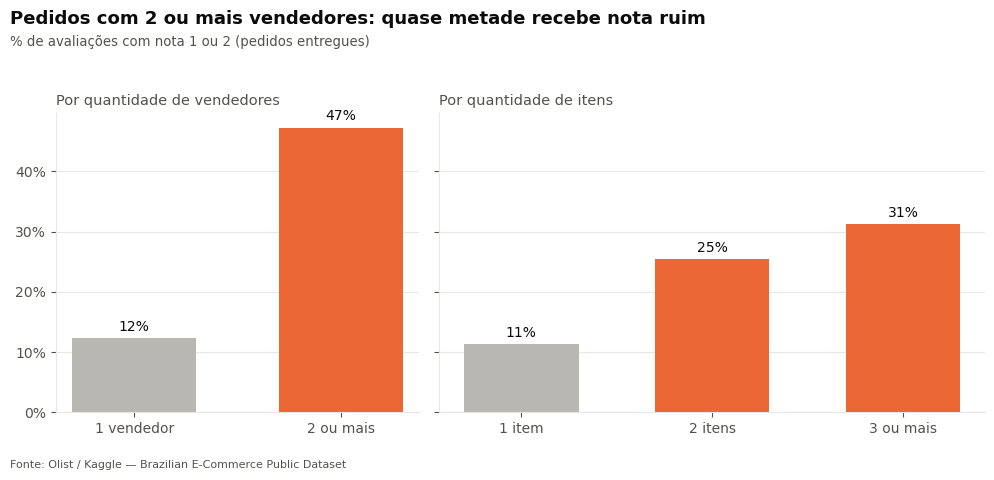

In [3]:
entregues["vendedores"] = entregues["qtd_vendedores"].map(lambda n: "1 vendedor" if n == 1 else "2 ou mais")
entregues["itens"] = entregues["qtd_itens"].map({1: "1 item", 2: "2 itens"}).fillna("3 ou mais")

por_vendedores = entregues.groupby("vendedores").agg(
    qtd_pedidos=("review_id", "count"), nota_media=("review_score", "mean"), porcentagem_notas_ruins=("nota_ruim", "mean"))
por_itens = entregues.groupby("itens").agg(
    qtd_pedidos=("review_id", "count"), nota_media=("review_score", "mean"), porcentagem_notas_ruins=("nota_ruim", "mean"))
for tabela in (por_vendedores, por_itens):
    tabela["porcentagem_notas_ruins"] *= 100
display(por_vendedores.round(2), por_itens.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True, gridspec_kw={"width_ratios": [2, 3]})
for ax, tabela, titulo in [(ax1, por_vendedores, "Por quantidade de vendedores"), (ax2, por_itens, "Por quantidade de itens")]:
    cores = [CINZA] + [LARANJA] * (len(tabela) - 1)
    barras = ax.bar(tabela.index, tabela["porcentagem_notas_ruins"], color=cores, width=0.6)
    ax.bar_label(barras, labels=[f"{v:.0f}%" for v in tabela["porcentagem_notas_ruins"]], padding=3, color=TEXTO)
    ax.set_title(titulo, fontsize=10.5, fontweight="normal", color=TEXTO_2)
    ax.grid(axis="x", visible=False)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.suptitle("Pedidos com 2 ou mais vendedores: quase metade recebe nota ruim", x=0.01, ha="left",
             fontweight="bold", fontsize=13, color=TEXTO)
fig.text(0.01, 0.9, "% de avaliações com nota 1 ou 2 (pedidos entregues)", color=TEXTO_2, fontsize=9.5)
fig.tight_layout(rect=(0, 0, 1, 0.9))
fonte(fig)
salvar(fig, "09_vendedores_e_itens")
plt.show()

## 4.2 O que os clientes reclamam quando o pedido chegou no prazo

Classificação simples dos comentários por palavras-chave. É uma aproximação: um comentário pode cair em
mais de um tema ou em nenhum.

comentários analisados: 6532


Produto errado / diferente    11.3
Defeito / qualidade           15.2
Pedido incompleto             19.4
dtype: float64

entre pedidos com 2+ vendedores, 'Pedido incompleto': 43.1%


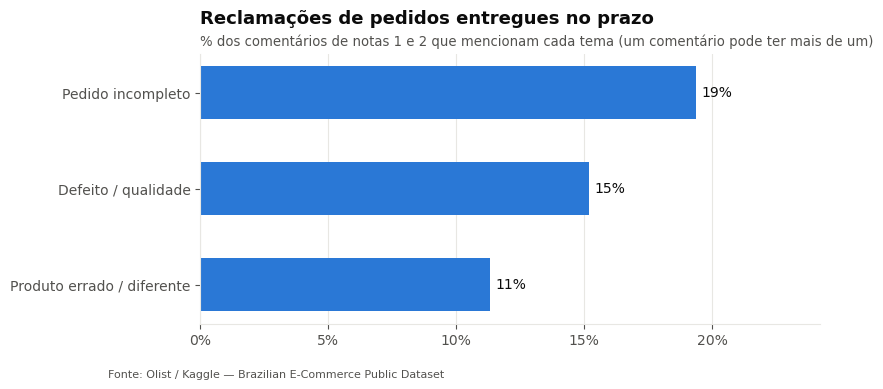

In [4]:
temas = {
    "Pedido incompleto": r"apenas um|apenas 1|só um|so um|só 1|somente um|faltou|falta|faltando|metade|não veio|nao veio|recebi um",
    "Defeito / qualidade": r"defeito|quebrad|danificad|não funciona|nao funciona|qualidade|falsificad|frágil|fragil",
    "Produto errado / diferente": r"errad|diferente|trocad|outro produto|não era|nao era",
}

ruins_no_prazo_com_comentario = ruins.loc[~ruins["entrega_atrasada"] & ruins["review_comment_message"].notna()].copy()
comentarios = ruins_no_prazo_com_comentario["review_comment_message"].str.lower()
for tema, padrao in temas.items():
    ruins_no_prazo_com_comentario[tema] = comentarios.str.contains(padrao, regex=True)

porcentagem_temas = (ruins_no_prazo_com_comentario[list(temas)].mean() * 100).sort_values()
print(f"comentários analisados: {len(ruins_no_prazo_com_comentario)}")
display(porcentagem_temas.round(1))

multi_vendedor = ruins_no_prazo_com_comentario["qtd_vendedores"] > 1
print(f"entre pedidos com 2+ vendedores, '{list(temas)[0]}': "
      f"{ruins_no_prazo_com_comentario.loc[multi_vendedor, 'Pedido incompleto'].mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 3.5))
barras = ax.barh(porcentagem_temas.index, porcentagem_temas.values, color=AZUL, height=0.55)
ax.bar_label(barras, labels=[f"{v:.0f}%" for v in porcentagem_temas.values], padding=4, color=TEXTO)
ax.set_title("Reclamações de pedidos entregues no prazo", pad=22)
subtitulo(ax, "% dos comentários de notas 1 e 2 que mencionam cada tema (um comentário pode ter mais de um)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.xaxis.set_major_locator(mtick.MultipleLocator(5))
ax.set_xlim(0, porcentagem_temas.max() * 1.25)
ax.grid(axis="y", visible=False)
fonte(fig)
salvar(fig, "10_temas_das_reclamacoes")
plt.show()

Curiosidade da limpeza: a Olist anonimizou os nomes das lojas trocando por casas de *Game of Thrones*,
então aparecem comentários como *"comprei na lannister..."*.

In [5]:
print("comentários que citam 'lannister':",
      base["review_comment_message"].str.contains("lannister", case=False, na=False).sum())
print(f"notas ruins com comentário: {entregues.loc[entregues['nota_ruim'], 'review_comment_message'].notna().mean() * 100:.0f}%")
print(f"notas boas com comentário:  {entregues.loc[~entregues['nota_ruim'], 'review_comment_message'].notna().mean() * 100:.0f}%")

comentários que citam 'lannister': 1208
notas ruins com comentário: 75%
notas boas com comentário:  35%


## 4.3 Categorias com mais notas ruins mesmo entregando no prazo

Só categorias com pelo menos 500 avaliações de pedidos entregues no prazo.

,qtd_reviews,porcentagem_notas_ruins,nota_media
product_category_name,,,
moveis_escritorio,1146,18.50,3.76
cama_mesa_banho,8529,11.98,4.15
moveis_decoracao,5759,11.39,4.21
informatica_acessorios,6122,11.39,4.20
telefonia,3766,10.73,4.18
relogios_presentes,5049,9.82,4.27
eletroportateis,577,9.53,4.36
eletronicos,2294,9.15,4.27
bebes,2529,9.09,4.30


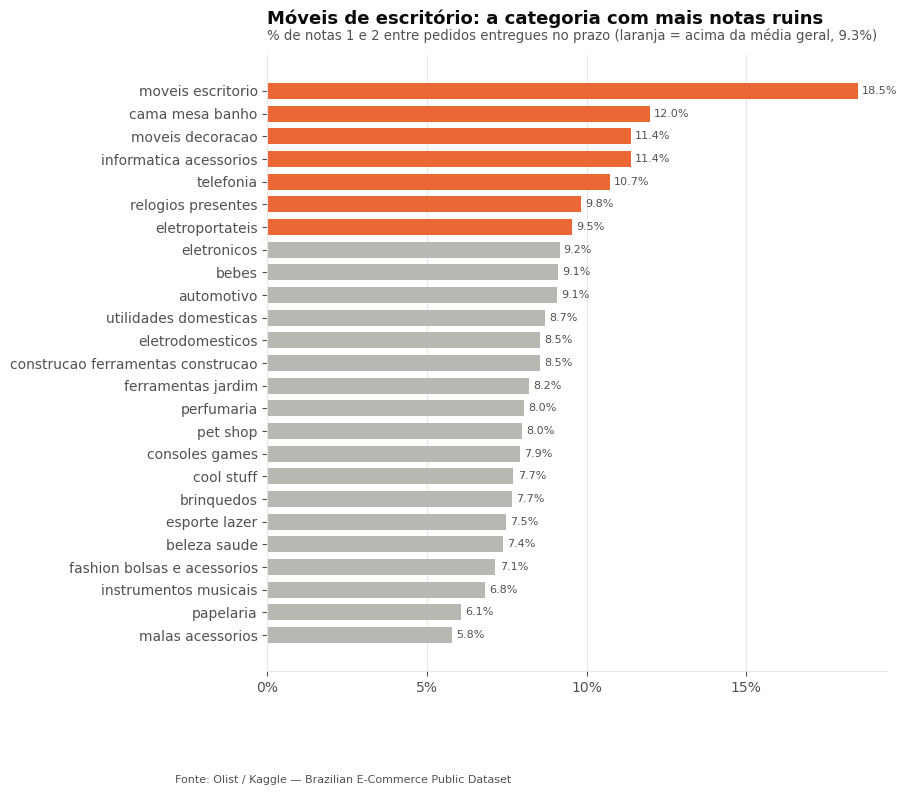

In [6]:
no_prazo = entregues.loc[~entregues["entrega_atrasada"]]
por_categoria = no_prazo.groupby("product_category_name").agg(
    qtd_reviews=("review_id", "count"), porcentagem_notas_ruins=("nota_ruim", "mean"), nota_media=("review_score", "mean"))
por_categoria["porcentagem_notas_ruins"] *= 100
por_categoria = por_categoria.loc[por_categoria["qtd_reviews"] >= 500].sort_values("porcentagem_notas_ruins")
media_geral = no_prazo["nota_ruim"].mean() * 100
display(por_categoria.sort_values("porcentagem_notas_ruins", ascending=False).round(2))

fig, ax = plt.subplots(figsize=(8, 8))
cores = [LARANJA if v > media_geral else CINZA for v in por_categoria["porcentagem_notas_ruins"]]
barras = ax.barh(por_categoria.index.str.replace("_", " "), por_categoria["porcentagem_notas_ruins"], color=cores, height=0.7)
ax.bar_label(barras, labels=[f"{v:.1f}%" for v in por_categoria["porcentagem_notas_ruins"]], padding=3, color=TEXTO_2, fontsize=8)
ax.set_title("Móveis de escritório: a categoria com mais notas ruins", pad=22)
subtitulo(ax, f"% de notas 1 e 2 entre pedidos entregues no prazo (laranja = acima da média geral, {media_geral:.1f}%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.xaxis.set_major_locator(mtick.MultipleLocator(5))
ax.grid(axis="y", visible=False)
fonte(fig)
salvar(fig, "11_categorias_no_prazo")
plt.show()

## 4.4 Hipóteses que não se confirmaram

### O frete caro gera notas ruins?
Dividindo os pedidos em 5 grupos pelo peso do frete em relação ao valor dos produtos:

In [7]:
entregues["frete_sobre_produto"] = entregues["valor_frete"] / entregues["valor_produtos"]
entregues["grupo_frete"] = pd.qcut(entregues["frete_sobre_produto"], 5,
                                   labels=["muito barato", "barato", "médio", "caro", "muito caro"])
entregues.groupby("grupo_frete", observed=True).agg(
    frete_sobre_produto_mediana=("frete_sobre_produto", "median"),
    nota_media=("review_score", "mean"),
    porcentagem_notas_ruins=("nota_ruim", lambda s: s.mean() * 100),
).round(3)

,frete_sobre_produto_mediana,nota_media,porcentagem_notas_ruins
grupo_frete,,,
muito barato,0.079,4.203,12.375
barato,0.149,4.177,12.313
médio,0.225,4.163,12.381
caro,0.336,4.126,13.506
muito caro,0.623,4.109,13.507


A nota quase não muda (de ~4,20 para ~4,11). **O valor do frete não parece ser um fator importante** para a avaliação.

### E os pedidos que nunca chegaram?

In [8]:
nao_entregues = base.loc[base["entrega_atrasada"].isna()]
print(f"reviews de pedidos não entregues: {len(nao_entregues)} | nota média: {nao_entregues['review_score'].mean():.2f}")
nao_entregues["order_status"].value_counts()

reviews de pedidos não entregues: 2865 | nota média: 1.76


order_status
shipped        1043
canceled        603
unavailable     597
invoiced        313
processing      296
delivered         8
created           3
approved          2
Name: count, dtype: int64

## Conclusões do capítulo

- Pedidos com **2 ou mais vendedores** têm nota média 2,86 e **47%** de notas ruins (contra 12% com 1 vendedor).
  Nas reclamações desses pedidos, 43% falam de pedido incompleto.
- Entre as notas ruins de pedidos entregues no prazo, os temas mais comuns são **pedido incompleto**,
  **defeito/qualidade** e **produto errado**.
- **Móveis de escritório** se destaca com 18,5% de notas ruins mesmo entregando no prazo.
- O **valor do frete** quase não muda a nota.
- Pedidos que nunca chegaram têm nota média 1,76 — praticamente todos nota 1.